# HW3 - Neural Network Model of BTS Data

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, roc_curve, recall_score

In [2]:
# Import raw data file

# input_file = "On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2026_1.csv"
# df = pd.read_csv(input_file)

# condition = (df["Origin"] == "ORD") # & (df["Reporting_Airline"] == "UA")

# df_filtered = df[condition]

# columns_to_keep = [
#     "CRSDepTime", # [hhmm]
#     # "CRSArrTime",
#     "Distance", # [mile]
#     "CRSElapsedTime", # [min]
#     "ArrDel15" # binary
# ]

# fdata = df_filtered[columns_to_keep].copy()

# for col in columns_to_keep:
#     fdata[col] = pd.to_numeric(fdata[col], errors="coerce")

# fdata = fdata.dropna(subset=columns_to_keep) # delete N/A data

# hours = fdata["CRSDepTime"] // 100 # change "hhmm" to [hrs] of the day
# minutes = fdata["CRSDepTime"] % 100

# fdata["CRSDepTime_hr"] = np.where(
#     fdata["CRSDepTime"] > 0, hours + minutes/60, 0.0
# )

# fdata["CRSElapsedTime_hr"] = np.where(
#     fdata["CRSElapsedTime"] > 0, fdata["CRSElapsedTime"] / 60, 0.0
# )

# fdata.to_csv("dataset_cleaned.csv", index=False)

fdata = pd.read_csv("dataset_cleaned.csv")
print(fdata.head())

   CRSDepTime  Distance  CRSElapsedTime  ArrDel15  CRSDepTime_hr  \
0        1010    4243.0           547.0       0.0      10.166667   
1        1010    4243.0           547.0       0.0      10.166667   
2        1010    4243.0           547.0       0.0      10.166667   
3        1010    4243.0           547.0       1.0      10.166667   
4        1010    4243.0           547.0       0.0      10.166667   

   CRSElapsedTime_hr  
0           9.116667  
1           9.116667  
2           9.116667  
3           9.116667  
4           9.116667  


In [3]:
# Load Data
X_df = fdata[['CRSDepTime_hr', 'Distance', 'CRSElapsedTime_hr']]
y_df = fdata['ArrDel15']

X = X_df.to_numpy()
y = y_df.to_numpy()

# Split Data: Train 80%, Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 10,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("")
print("Test dataset class distribution:")
print(pd.Series(y_test).value_counts(normalize=True))

X_train: (19301, 3)
X_test: (4826, 3)
y_train: (19301,)
y_test: (4826,)

Test dataset class distribution:
0.0    0.67385
1.0    0.32615
Name: proportion, dtype: float64


In [4]:
# scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Dataset Explanation**

***Use the same dataset at HW2***

The primary objective of this analysis is to investigate the operational factors influencing airplane arrival delays. I define an arrival delay as a delay of 15 minutes or more and classify it as a binary outcome (ArrDel15; 0 = not delayed, 1 = delayed). I hypothesize that its occurance is predominantly associated with scheduled departure time (CRSDepTime), distance (Distance), and scheduled elasped time (CRSElapsedTime). I chose these predictors because they are known in advance, whereas variables such as taxi-out time, actual departure time, and actual flight duration are not available prior to departure.

To reduce variation from other factors, I focuse on a controlled subset of flights departing from Chicago O'Hare International Airport (ORD). In addition, both scheuled departure time and elasped time are converted to hours for easier interpretation.

The dataset was split into training and test sets using an 80/20 ratio. In the test set, 67.4% of the obervations belong to class 0, while 32.6% belong to class 1. The features were scaled to prevent large values from dominating the weight calculations.

### Neural Networks Model

In [5]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

In [6]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [7]:
# Model
class Net(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(3,32) # input: 3
        self.fc2 = nn.Linear(32,8)
        self.fc3 = nn.Linear(8,1) # output: 1

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x

net = Net()

In [8]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.SGD( # Adam
    net.parameters(),
    lr=0.01
)

***Model Explanation***

Constructed a neural network model with three input features and two hidden layers containing 32 and 8 neurons, respectively, using LeLU activation functions. The output layer contains one neuron for binary classification. To train the model, used mini-batch training with a batch size of 64. The binary cross entropy loss (BCEWithLogitsLoss) was used as the loss function, which is appropriate for binary classification. The model parameters were optimized using SGD (also tried Adam) with a learning rate of 0.01.

In [9]:
num_epochs = 100
loss_history = []

for epoch in range(num_epochs):

    net.train()

    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = net(X_batch) # forward

        loss = criterion(outputs, y_batch)

        loss.backward() # backward

        optimizer.step()

        epoch_loss += loss.item()

    # Average loss
    epoch_loss /= len(train_loader)

    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{num_epochs}, "
            f"Loss: {loss.item():.4f}"
        )

Epoch 10/100, Loss: 0.5755
Epoch 20/100, Loss: 0.5596
Epoch 30/100, Loss: 0.6571
Epoch 40/100, Loss: 0.6510
Epoch 50/100, Loss: 0.6543
Epoch 60/100, Loss: 0.6190
Epoch 70/100, Loss: 0.4963
Epoch 80/100, Loss: 0.5687
Epoch 90/100, Loss: 0.6437
Epoch 100/100, Loss: 0.6099


In [10]:
# Train
outputs = net(X_train_tensor)

loss = criterion(outputs, y_train_tensor)

loss.backward()

optimizer.step()

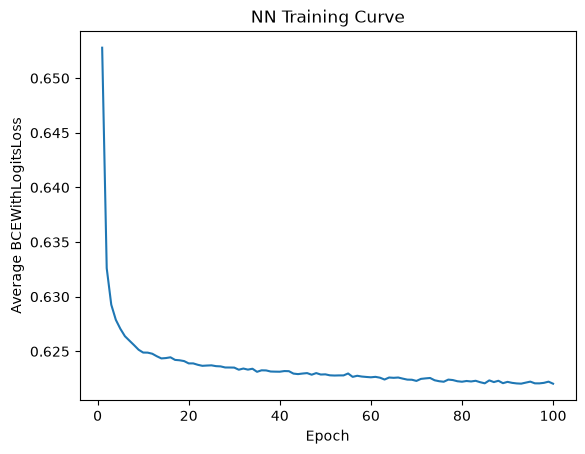

In [11]:
plt.plot(range(1, num_epochs + 1), loss_history)

plt.xlabel("Epoch")
plt.ylabel("Average BCEWithLogitsLoss")
plt.title("NN Training Curve")

plt.show()

***Training***

The training loss decreases rapidly during the first few epochs and then gradually converges. This indicates that the NN is learning effectively and converging as the number of epochs increases. After about 20 epochs, the loss decreases slightly, suggesting that additional training provides relatively small improvements.

In [12]:
net.eval()

with torch.no_grad():

    outputs = net(X_test_tensor)

    y_prob_nn = torch.sigmoid(outputs)

    y_pred_nn = (y_prob_nn >= 0.5).float() # threshold = 0.5

In [13]:
# Test accuracy
test_accuracy_nn = (
    y_pred_nn == y_test_tensor
).float().mean().item()

# Test error
test_error_nn = 1 - test_accuracy_nn


print(f"NN Test Accuracy: {test_accuracy_nn:.4f}")
print(f"NN Test Error: {test_error_nn:.4f}")

NN Test Accuracy: 0.6738
NN Test Error: 0.3262


In [14]:
y_prob_nn = np.asarray(y_prob_nn).reshape(-1)
y_pred_nn = np.asarray(y_pred_nn).reshape(-1)
y_test_eval = np.asarray(y_test).reshape(-1)

In [15]:
err_nn = np.mean(y_pred_nn != y_test)

auc_nn = roc_auc_score(
    y_test,
    y_prob_nn
)

recall_nn = recall_score(
    y_test,
    y_pred_nn
)

print("<Neural Network>")
print("Test Error Rate:", err_nn)
print("AUC:", auc_nn)
print("Recall:", recall_nn)

<Neural Network>
Test Error Rate: 0.32615002072109406
AUC: 0.5909884797704393
Recall: 0.0


***Test***

The model achieved a test accurcay of 67.4% and a test error rate of 32.6%. These values are almost identical to the class distribution in the dataset, where 67/4% of flights are not delayed and 32.6% are delayed. This suggests that the neural network may be predicting most observations as the majority class (not delayed). This is further supported by a recall of 0.0, indicating that the model faild to correctly identify any of the delayed flights at the 0.5 classification threshold. Also, AUC of 0.595 is slightly above 0.5, suggesting weak discrimiation between delayed and non-delayed flights. Therefore, although the accuracy is approximately 67.4%, the model has limited ability to identify delayed flights.

Additionally, when the classification threshold was lowered from 0.5 to 0.3, the recall increased from 0 to 0.686, indicating that the model was able to idenfity the delayed flights, and many delayed flights received predicted probabilities between 0.3 and 0.5. However, the test error rate also increased; this demonstrates a lower threshold makes the model more sensitive to delays, but it also increases the non-delayed flights incorrectly classified as delayed.

Result (threshold = 0.3)

Test Error Rate: 0.4927476170741815

AUC: 0.5950110263491453

Recall: 0.6855146124523507

## KNN Model

In [16]:
k = 50

knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(
    X_train_scaled,
    y_train
)

y_knn = knn.predict(X_test_scaled)

y_prob_knn = knn.predict_proba(
    X_test_scaled
)[:, 1]


err_knn = np.mean(
    y_knn != y_test
)

auc_knn = roc_auc_score(
    y_test,
    y_prob_knn
)

recall_knn = recall_score(
    y_test,
    y_knn
)

In [17]:
print("KNN Classifier")
print("Test Error Rate:", err_knn)
print("AUC:", auc_knn)
print("Recall:", recall_knn)

print()

print("Neural Network")
print("Test Error Rate:", err_nn)
print("AUC:", auc_nn)
print("Recall:", recall_nn)

KNN Classifier
Test Error Rate: 0.32967260671363446
AUC: 0.5788479692293746
Recall: 0.0698856416772554

Neural Network
Test Error Rate: 0.32615002072109406
AUC: 0.5909884797704393
Recall: 0.0


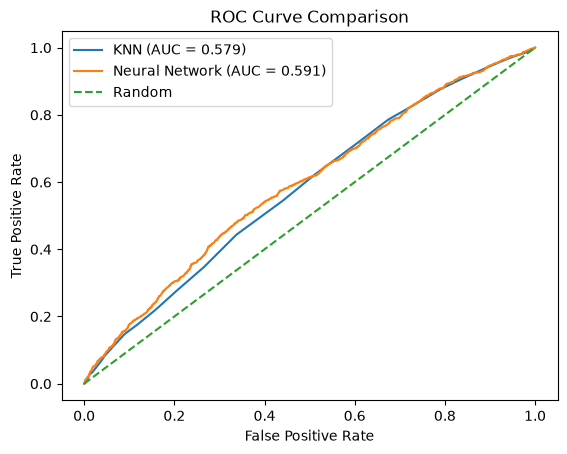

In [18]:
fpr_knn, tpr_knn, _ = roc_curve(
    y_test,
    y_prob_knn
)

fpr_nn, tpr_nn, _ = roc_curve(
    y_test,
    y_prob_nn
)


plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot(
    fpr_nn,
    tpr_nn,
    label=f"Neural Network (AUC = {auc_nn:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

***KNN vs. NN***

The KNN and neural network showed similar overall performance. The ROC curves are also close to each other and only moderately above the random-classifier line, indicating that both models have limited ability to distinguish between delayed and non-delayed flights. Although KNN achieved a higher recall than the NN at the 0.5 threshold, both models struggled to idenfity delayed flights.Overall NN performed slightly better in terms of test error and AUC, but neither model provided strong predictive performance.